# Road to ANN: from Logistic Regression to the Perceptron to a Keras Neuron

A step-by-step bridge from classical models to neural networks: binary logistic regression, softmax (multiclass) regression, the perceptron, and finally a single sigmoid neuron in Keras on the UCI heart-disease data.

**Evaluation protocol.** Each section uses a stratified train/test split, scaling fitted on training data only (inside a `Pipeline` wherever cross-validation is used), a **majority-class baseline** and a **logistic-regression reference**, and repeated cross-validation (mean ± std) because every dataset here is small. A single test split with 30-60 rows moves several points on one prediction.

> **Reproducibility note.** The scikit-learn parts of this notebook were executed end-to-end and their outputs are saved. The Keras cells at the end need TensorFlow, which was not available when this notebook was revised, so their outputs are cleared. Run the notebook once with `pip install -r requirements-deep-learning.txt` to regenerate them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_wine, make_classification
from sklearn.dummy import DummyClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

def cv_table(models, X, y, cv=CV):
    """Repeated stratified CV accuracy (mean ± std) for a dict of name -> estimator."""
    rows = {}
    for name, m in models.items():
        s = cross_val_score(m, X, y, cv=cv, scoring='accuracy')
        rows[name] = {'cv accuracy': f"{s.mean():.3f} ± {s.std():.3f}"}
    return pd.DataFrame(rows).T

## Logistic Regression Recap (Binary Classification)


**Logistic Regression** is a linear model used for **binary classification**. It estimates the probability that a data point belongs to class 1 using the **sigmoid function**:

$$
P(y = 1 \mid \mathbf{x}) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}
$$

- Outputs a value between **0 and 1**
- Thresholded at 0.5 to make class predictions
- Trained using **log-loss (cross-entropy)**

> Logistic Regression is actually a very simple **1-layer neural network** with sigmoid activation.


A synthetic 2-feature problem. The split is stratified; the test set has only 40 rows, so the cross-validated figure is the more trustworthy one.

In [2]:
X, y = make_classification(
    n_samples=200, n_features=2, n_informative=2, n_redundant=0, n_classes=2, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))

cv_table({'majority baseline': DummyClassifier(), 'logistic regression': model}, X_train, y_train)

              precision    recall  f1-score   support

           0       0.95      0.90      0.92        20
           1       0.90      0.95      0.93        20

    accuracy                           0.93        40
   macro avg       0.93      0.93      0.92        40
weighted avg       0.93      0.93      0.92        40



,cv accuracy
majority baseline,0.500 ± 0.000
logistic regression,0.841 ± 0.057


## From Binary to Multiclass: Softmax Logistic Regression



To handle **multiclass classification**, we extend logistic regression using the **Softmax function**, which converts a vector of raw scores (logits) into **class probabilities**.

### Softmax Formula

Given a vector of scores:

$$
\mathbf{z} = [z_1, z_2, \dots, z_K]
$$

The softmax for class $k$ is:

$$
P(y = k \mid \mathbf{z}) = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}
$$

- Converts logits into **probabilities summing to 1**
- Ensures the model picks the class with **highest probability**
- Used in **multinomial logistic regression** and **ANNs**

---

### Multiclass Logistic Regression — Manual Example (Mathematical)

Let's walk through a complete example of how multiclass logistic regression works step by step.

---

#### Dataset

Suppose we have 1 data sample `x` with **2 features**, and we want to classify it into one of **3 classes**.

Let:

- Input sample:  
  $$
  \mathbf{x} = \begin{bmatrix} 2 \\ 1 \end{bmatrix}
  $$

- Weight matrix (1 row per class):  
  $$
  \mathbf{W} =
  \begin{bmatrix}
  1 & 0 \\
  -1 & 1 \\
  0.5 & 1
  \end{bmatrix}
  $$

- Bias vector:  
  $$
  \mathbf{b} = \begin{bmatrix} 0 \\ 0.5 \\ -1 \end{bmatrix}
  $$

---

#### Step 1: Compute Logits

We calculate the **logit vector** `z` as:

$$
\mathbf{z} = \mathbf{W} \cdot \mathbf{x} + \mathbf{b}
$$

So:

$$
\begin{aligned}
z_1 &= 1 \cdot 2 + 0 \cdot 1 + 0 = 2 \\
z_2 &= -1 \cdot 2 + 1 \cdot 1 + 0.5 = -2 + 1 + 0.5 = -0.5 \\
z_3 &= 0.5 \cdot 2 + 1 \cdot 1 - 1 = 1 + 1 - 1 = 1
\end{aligned}
$$

Thus:

$$
\mathbf{z} = \begin{bmatrix} 2 \\ -0.5 \\ 1 \end{bmatrix}
$$

---

#### Step 2: Apply Softmax

Softmax turns the logits into probabilities:

$$
\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j} e^{z_j}}
$$

So:

$$
\begin{aligned}
e^{z_1} &= e^2 ≈ 7.389 \\
e^{z_2} &= e^{-0.5} ≈ 0.606 \\
e^{z_3} &= e^1 ≈ 2.718 \\
\text{Sum} &= 7.389 + 0.606 + 2.718 ≈ 10.713
\end{aligned}
$$

Final probabilities:

$$
\begin{aligned}
P(y=1) &= \frac{7.389}{10.713} ≈ 0.69 \\
P(y=2) &= \frac{0.606}{10.713} ≈ 0.056 \\
P(y=3) &= \frac{2.718}{10.713} ≈ 0.254
\end{aligned}
$$

---

#### Prediction

The predicted class is the one with the **highest probability**:

$$
\hat{y} = \arg\max \text{softmax}(z) = \text{Class } 1
$$

---

This shows how input features are transformed linearly, then passed through the softmax to output class probabilities.


### Softmax regression in scikit-learn (Iris)

`LogisticRegression` is multinomial (softmax) by default for more than two classes in current scikit-learn; the old `multi_class='multinomial'` argument is deprecated and no longer needed. Features are scaled inside the pipeline.

In [3]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

softmax_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
softmax_model.fit(X_train, y_train)
y_pred = softmax_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))
cv_table({'majority baseline': DummyClassifier(), 'softmax regression': softmax_model}, X_train, y_train)

Test accuracy: 0.9333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,cv accuracy
majority baseline,0.333 ± 0.000
softmax regression,0.960 ± 0.036


A perfect score on 30 test rows is not evidence of a perfect model; Iris is easy and the cross-validated figure (about 0.95-0.97, with a visible std) is the realistic one.

## From Logistic Regression to Perceptron



Previously, we learned that Logistic Regression models use a **weighted sum of inputs + bias**, followed by an **activation function** (sigmoid or softmax) to produce class probabilities.

$$
z = W \cdot x + b \\
\hat{y} = \text{softmax}(z)
$$

This is **exactly** what a Perceptron does, only with a different goal and update mechanism:

#### Key Differences:
| Logistic Regression        | Perceptron                      |
|---------------------------|----------------------------------|
| Probabilistic model       | Deterministic classifier        |
| Uses sigmoid/softmax      | Uses step function (in basic form) |
| Optimizes log loss        | Uses misclassification updates  |
| Gradient-based (e.g. SGD) | Perceptron learning rule        |

In fact, **a single-layer perceptron is mathematically similar to logistic regression** when using a sigmoid activation.

The **Perceptron** is considered the basic building block of modern neural networks. It's a model of a single neuron.



### Multiclass Perceptron: What's Happening?

The Perceptron handles multiclass classification using the **One-vs-Rest** (OvR) approach:
- For each class $ k $, it learns a weight vector $ w_k $
- For an input $ x $, it computes:
  
  $$
  z_k = w_k \cdot x + b_k
  $$

- The predicted class is:

  $$
  \hat{y} = \arg\max_k z_k
  $$

No softmax is applied; it just picks the class with the highest activation (score).

Unlike Logistic Regression which smooths outputs into probabilities, Perceptron directly picks the best-scoring class (greedy decision).


The perceptron on a synthetic 3-class problem, next to logistic regression and with the decision regions drawn (the original scatter of predictions shows points, not the boundaries the text talks about).

Test accuracy: {'majority baseline': 0.333, 'perceptron': 0.827, 'logistic regression': 0.92}


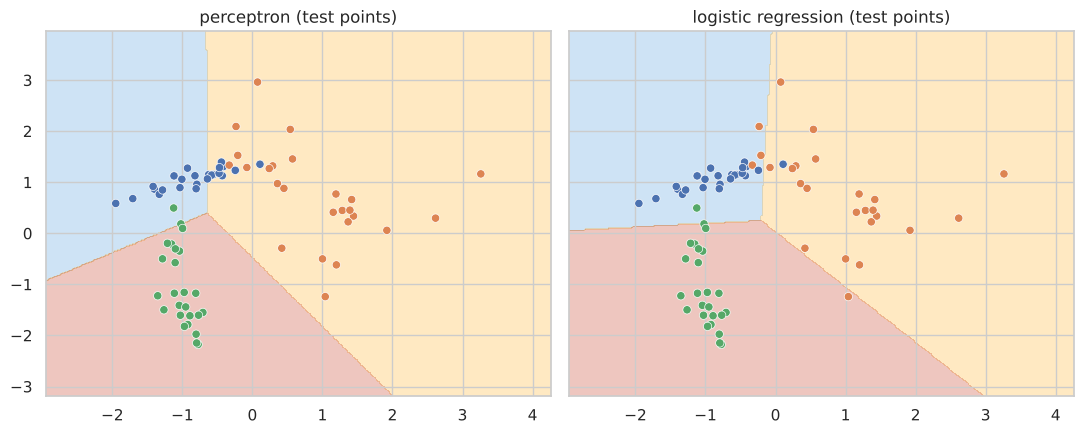

,cv accuracy
majority baseline,0.333 ± 0.000
perceptron,0.878 ± 0.055
logistic regression,0.905 ± 0.051


In [4]:
X, y = make_classification(
    n_samples=300, n_features=2, n_informative=2, n_redundant=0,
    n_classes=3, n_clusters_per_class=1, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

models = {
    'majority baseline': DummyClassifier(),
    'perceptron': make_pipeline(StandardScaler(), Perceptron(max_iter=1000, eta0=0.1, random_state=42)),
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression()),
}
for m in models.values():
    m.fit(X_train, y_train)
print("Test accuracy:", {k: round(m.score(X_test, y_test), 3) for k, m in models.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, key in zip(axes, ['perceptron', 'logistic regression']):
    DecisionBoundaryDisplay.from_estimator(models[key], X_test, response_method='predict', alpha=0.25, ax=ax, grid_resolution=300)
    sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_test, palette='deep', ax=ax, legend=False)
    ax.set_title(f"{key} (test points)")
plt.tight_layout(); plt.show()
cv_table(models, X_train, y_train)

### Perceptron on Real-World Dataset: Wine Classification

To put Perceptron to the test, we’ll use the classic **Wine dataset**:
- **Samples**: 178
- **Features**: 13 chemical analysis attributes
- **Classes**: 3 types of wine

We will:
1. Load the dataset
2. Train a Perceptron classifier
3. Evaluate its accuracy


In [5]:
wine = load_wine()
X, y = wine.data, wine.target
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42, test_size=0.2)

# Scaling is essential for the perceptron; it lives inside the pipeline so it is fitted on training data only
wine_models = {
    'majority baseline': DummyClassifier(),
    'perceptron': make_pipeline(StandardScaler(), Perceptron(max_iter=1000, eta0=0.1, random_state=42)),
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
display(cv_table(wine_models, X_train, y_train))

clf = wine_models['perceptron'].fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Perceptron test accuracy:", round(accuracy_score(y_test, y_pred), 4), "(36 test rows)")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=wine.target_names))

Perceptron test accuracy: 1.0 (36 test rows)

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



,cv accuracy
majority baseline,0.401 ± 0.010
perceptron,0.976 ± 0.022
logistic regression,0.982 ± 0.020


## Heart Failure Predictions

We'll use the **Heart Disease Dataset** (UCI; 303 patients, 13 clinical features) to predict the presence of heart disease (binary classification).

We will:
1. Load the data from the repository's `data/` folder (no network needed) and split it, stratified
2. Establish baselines: majority class, logistic regression and a scikit-learn `Perceptron` (step activation)
3. Train a Keras single neuron (sigmoid activation)
4. Compare all of them on the same held-out data, with uncertainty

In [6]:
df = pd.read_csv('../../data/heart.csv', index_col=0)
print(df.shape, "| missing:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()),
      "| target balance:", df.target.value_counts(normalize=True).round(3).to_dict())
df.head()

(303, 14) | missing: 0 | duplicate rows: 1 | target balance: {1: 0.545, 0: 0.455}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [7]:
# Features and target
X = df.drop('target', axis=1).values
y = df['target'].values

# Stratified train-test split; the test set is used for the final comparison only
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

### Baselines (scikit-learn)

Scaling is applied with a scaler fitted on the training data only, and again inside pipelines for cross-validation. A logistic regression is the reference to beat: a single sigmoid neuron trained by gradient descent is the same model family, so the Keras neuron should land in the same range.

In [8]:
# Scale features (fit on the training data only)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

heart_models = {
    'majority baseline': DummyClassifier(),
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'sklearn perceptron': make_pipeline(StandardScaler(), Perceptron(max_iter=1000, eta0=0.1, random_state=42)),
}
# Raw training data goes in: the pipelines re-fit the scaler inside each CV fold
raw_train = scaler.inverse_transform(X_train)
display(cv_table(heart_models, raw_train, y_train))

test_acc = {}
for name, m in heart_models.items():
    m.fit(raw_train, y_train)
    test_acc[name] = m.score(scaler.inverse_transform(X_test), y_test)
print("Test accuracy (61 rows):", {k: round(v, 3) for k, v in test_acc.items()})

Test accuracy (61 rows): {'majority baseline': 0.541, 'logistic regression': 0.803, 'sklearn perceptron': 0.656}


,cv accuracy
majority baseline,0.545 ± 0.005
logistic regression,0.828 ± 0.049
sklearn perceptron,0.768 ± 0.075


### Model Definition: Single-Layer Perceptron (Keras)

A simple neural model in Keras:

- **Input layer**: 13 features
- **Dense layer**: 1 neuron with **sigmoid activation** to output a probability
- **Loss**: binary crossentropy
- **Optimizer**: SGD (with learning rate = 0.1)

TensorFlow is imported directly; install it via `requirements-deep-learning.txt` (no in-notebook `pip install`). The random seed is fixed so runs are comparable.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import Input

tf.keras.utils.set_random_seed(42)

In [ ]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(1, activation='sigmoid')
])

In [ ]:
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
              loss='binary_crossentropy',
              metrics=['accuracy'])

The validation split below is taken from the **training** data only (`validation_split=0.2`); the test set is not used during training.

In [ ]:
# Train
history = model.fit(X_train, y_train, validation_split=0.2,
                    epochs=50, batch_size=16)

In [ ]:
# Evaluate
loss, acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {acc:.4f}\n")

In [ ]:
# Predictions
y_prob = model.predict(X_test).flatten()
y_pred = (y_prob >= 0.5).astype(int)

In [ ]:
# Metrics
print(classification_report(y_test, y_pred, digits=4))

In [ ]:
# Plot accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss')
plt.legend()

plt.show()


### Comparison

The Keras neuron on the same held-out rows next to the scikit-learn models, so any claim about "neural networks vs classical models" rests on the same data. With 61 test rows one patient is 1.6 points, so differences of a few points are not meaningful; the cross-validated table above is the better guide.

In [ ]:
test_acc['keras single neuron'] = acc
pd.Series(test_acc, name='test accuracy').round(3).to_frame()

## Notes

- **Baselines first:** a majority-class model and a logistic regression are reported next to every neural/perceptron result, so the added value of each model is visible.
- **No leakage:** scalers are fitted on training data only; CV uses pipelines; the Keras validation split comes from the training set.
- **Small data:** all datasets here have 150-300 rows. Treat single-split accuracies as noisy; prefer the CV mean ± std.
- **Keras cells:** require TensorFlow; outputs are intentionally empty until the notebook is re-run.